# Aula 6 - Atividade Prática: Mercado Imobiliário de São Paulo
Idealmente, eu faria:
[0] Setup do projeto + Git init + primeiro commit + push
[1] Carregar dados
[2] Criar colunas derivadas
[3] Ritual de inspeção (shape, info, describe, isna, value_counts)
[4] Diagnóstico de qualidade (ausentes, duplicatas, sentinelas, negativos/zeros) → checkpoint git
[5] Definir e isolar registros válidos (filtro justificado)
[6] Agregações para responder perguntas de negócio (groupby)
[7] Estatística descritiva — tendência central (média, mediana, moda, ponderada, aparada)
[8] Estatística descritiva — dispersão (variância, desvio, MAD, IQR, outliers)
[9] Forma da distribuição (assimetria, curtose)
[10] Visualização (histograma, boxplot)

# Identificação do aluno

**Nome:** Hanna Vitória de Oliveira Silva **Matrícula:** 	20260040696


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from google.colab import files

#uploaded = files.upload()


## Carregamento dos dados

In [3]:
imoveis = pd.read_csv("/content/imoveis_sao_paulo - imoveis_sao_paulo.csv")


In [ ]:
print(imoveis.shape) # Verificando dimensões do banco de dados
display(imoveis.head())  # Verificação visual do Banco de dados

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29706 entries, 0 to 29705
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   bairro                29706 non-null  object 
 1   zona                  29706 non-null  object 
 2   tier                  29706 non-null  object 
 3   area                  29706 non-null  float64
 4   rooms                 29706 non-null  int64  
 5   parking spaces        29409 non-null  float64
 6   floor                 25252 non-null  float64
 7   total_floors          25252 non-null  float64
 8   transit_distance_min  29706 non-null  int64  
 9   furniture             29706 non-null  object 
 10  hoa (R$)              29201 non-null  float64
 11  rent amount (R$)      29706 non-null  float64
 12  property tax (R$)     29706 non-null  float64
 13  total (R$)            29706 non-null  float64
dtypes: float64(8), int64(2), object(4)
memory usage: 3.2+ MB


total_floors            4454
floor                   4454
hoa                      505
parking_spaces           297
zona                       0
bairro                     0
rooms                      0
area                       0
tier                       0
transit_distance_min       0
furniture                  0
rent_amount                0
property_tax               0
total                      0
dtype: int64


,area,rooms,parking_spaces,floor,total_floors,transit_distance_min,hoa,rent_amount,property_tax,total
count,29706.000000,29706.000000,29409.000000,25252.000000,25252.000000,29706.000000,29201.000000,29706.000000,29706.000000,29706.000000
mean,89.768279,2.255942,1.345438,6.423254,11.835855,61.594324,943.058765,4038.767212,536.333535,5521.569694
std,51.987653,1.252113,0.868646,5.185461,6.809877,74.597866,780.508252,3568.267510,464.259035,4374.821942
min,20.000000,0.000000,0.000000,1.000000,4.000000,0.000000,0.000000,220.000000,33.750000,480.000000
25%,54.500000,1.000000,1.000000,3.000000,8.000000,6.000000,475.000000,1660.000000,223.670000,2590.525000
50%,75.800000,2.000000,1.000000,5.000000,8.000000,38.000000,810.000000,2900.000000,386.250000,4190.000000
75%,110.100000,3.000000,2.000000,8.000000,15.000000,84.000000,1257.000000,5140.000000,685.825000,6936.162500
max,500.000000,6.000000,6.000000,25.000000,25.000000,623.000000,7176.000000,37710.000000,5221.200000,46020.000000


# 1. Padronização de dados

| Coluna | Significado | Unidade / valores possíveis |
|------------------------|------------------------|------------------------|
| `bairro` | Bairro de São Paulo onde o imóvel está localizado | ex.: Itaim Bibi, Mooca, Tucuruvi |
| `zona` | Região da cidade | Zona Sul, Zona Norte, Zona Leste, Zona Oeste, Centro |
| `tier` | Padrão do imóvel | affordable, mid, premium, luxury |
| `area` | Área útil do imóvel | m² |
| `rooms` | Quantidade de quartos | inteiro |
| `parking spaces` | Quantidade de vagas de garagem | inteiro |
| `floor` | Andar do imóvel | inteiro, ou ausente quando o imóvel não tem andar |
| `total_floors` | Total de andares do prédio | inteiro, ou ausente quando o imóvel não tem andares |
| `transit_distance_min` | Distância até a estação de metrô/trem mais próxima | minutos |
| `furniture` | Imóvel mobiliado | `furnished` / `not furnished` |
| `hoa (R$)` | Taxa de condomínio | R$/mês (pode ser `0`, um valor real) |
| `rent amount (R$)`| Valor do aluguel | R$/mês | |`property tax (R$)` | IPTU | R$/mês |
| `total (R$)` | Custo total do imóvel | R\$/mês (aluguel + condomínio + IPTU) |

In [ ]:
column_names = {
    "parking spaces": "parking_spaces",
    "hoa (R$)": "hoa",
    "rent amount (R$)": "rent_amount",
    "property tax (R$)": "property_tax",
    "total (R$)": "total"
}

imoveis = imoveis.rename(columns=column_names)
imoveis.head()  # Verifação do sucesso na mudança das colunas

*Escreva aqui sua interpretação.*

# 2. Qualidade dos dados

In [83]:
imoveis.info() # Tipos e não-nulos


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29706 entries, 0 to 29705
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   bairro                29706 non-null  object 
 1   zona                  29706 non-null  object 
 2   tier                  29706 non-null  object 
 3   area                  29706 non-null  float64
 4   rooms                 29706 non-null  int64  
 5   parking_spaces        29409 non-null  float64
 6   floor                 25252 non-null  float64
 7   total_floors          25252 non-null  float64
 8   transit_distance_min  29706 non-null  int64  
 9   furniture             29706 non-null  object 
 10  hoa                   29201 non-null  float64
 11  rent_amount           29706 non-null  float64
 12  property_tax          29706 non-null  float64
 13  total                 29706 non-null  float64
 14  furniture_num         29706 non-null  int64  
dtypes: float64(8), int6

In [84]:
print(imoveis.isna().sum().sort_values(ascending=False))  # Verificando valores ausentes e nulos


floor                   4454
total_floors            4454
hoa                      505
parking_spaces           297
zona                       0
tier                       0
bairro                     0
area                       0
rooms                      0
transit_distance_min       0
furniture                  0
rent_amount                0
property_tax               0
total                      0
furniture_num              0
dtype: int64


In [85]:
display(imoveis.describe())   # Resumo numérico

,area,rooms,parking_spaces,floor,total_floors,transit_distance_min,hoa,rent_amount,property_tax,total,furniture_num
count,29706.000000,29706.000000,29409.000000,25252.000000,25252.000000,29706.000000,29201.000000,29706.000000,29706.000000,29706.000000,29706.000000
mean,89.768279,2.255942,1.345438,6.423254,11.835855,61.594324,943.058765,4038.767212,536.333535,5521.569694,0.345856
std,51.987653,1.252113,0.868646,5.185461,6.809877,74.597866,780.508252,3568.267510,464.259035,4374.821942,0.475655
min,20.000000,0.000000,0.000000,1.000000,4.000000,0.000000,0.000000,220.000000,33.750000,480.000000,0.000000
25%,54.500000,1.000000,1.000000,3.000000,8.000000,6.000000,475.000000,1660.000000,223.670000,2590.525000,0.000000
50%,75.800000,2.000000,1.000000,5.000000,8.000000,38.000000,810.000000,2900.000000,386.250000,4190.000000,0.000000
75%,110.100000,3.000000,2.000000,8.000000,15.000000,84.000000,1257.000000,5140.000000,685.825000,6936.162500,1.000000
max,500.000000,6.000000,6.000000,25.000000,25.000000,623.000000,7176.000000,37710.000000,5221.200000,46020.000000,1.000000


*Escreva aqui sua interpretação.*

# 3. Perguntas de negócio

## 1. Quais bairros concentram a maior quantidade de casas?

/tmp/ipykernel_1951/1599015439.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


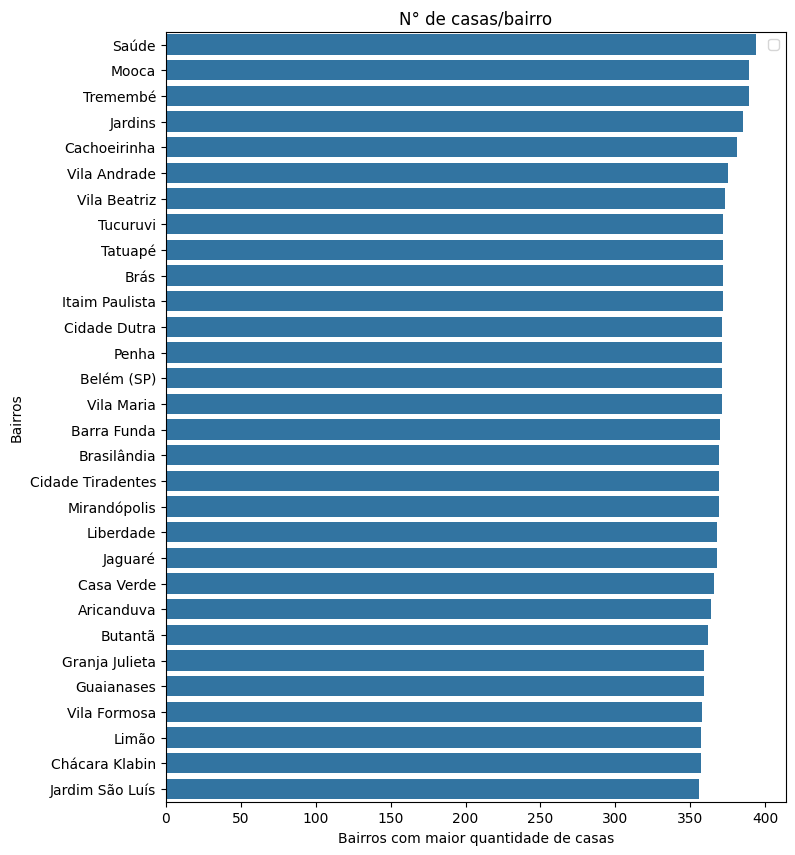

In [28]:
n_casas_bairro = imoveis["bairro"].value_counts().head(30);

fig, ax = plt.subplots(figsize=(8, 10))

sns.barplot(x=n_casas_bairro.values, y=n_casas_bairro.index, ax=ax, color="C0")

ax.set_xlabel("Bairros com maior quantidade de casas")
ax.set_ylabel("Bairros")
ax.set_title("N° de casas/bairro")
ax.legend()

plt.show()

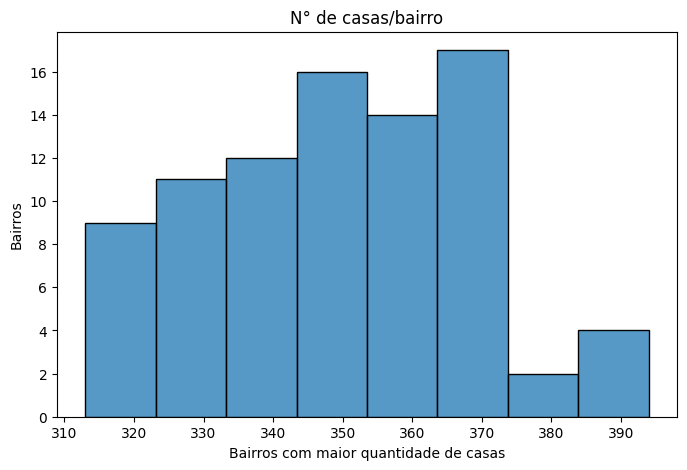

In [88]:
fig, ax = plt.subplots(figsize=(8, 5))
n_casas_bairro = imoveis["bairro"].value_counts();
sns.histplot(n_casas_bairro.values)
ax.set_title("Distribuição dos alugueis")

ax.set_xlabel("Bairros com maior quantidade de casas")
ax.set_ylabel("Bairros")
ax.set_title("N° de casas/bairro")
plt.show()

Percebemos aqui que a distribuição não segue uma norma
## 2. Qual a média de área e de aluguel por bairro?





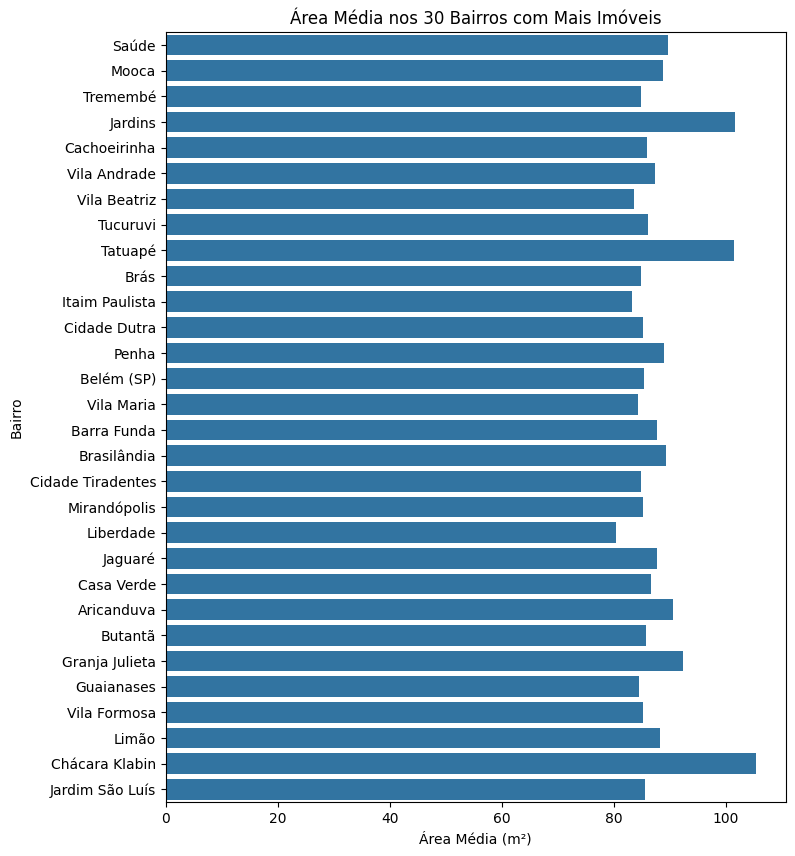

In [63]:

top_30_bairros = imoveis["bairro"].value_counts().head(30).index

area_top_30 = imoveis.groupby("bairro")["area"].mean().loc[top_30_bairros]

fig, ax = plt.subplots(figsize=(8, 10))

sns.barplot(x=area_top_30.values, y=area_top_30.index, ax=ax, color="C0")

ax.set_title("Área Média nos 30 Bairros com Mais Imóveis")
ax.set_xlabel("Área Média (m²)")
ax.set_ylabel("Bairro")
plt.show()

top_30_bairros = imoveis["bairro"].value_counts().head(30).index

area_top_30 = imoveis.groupby("bairro")["total"].mean().loc[top_30_bairros]


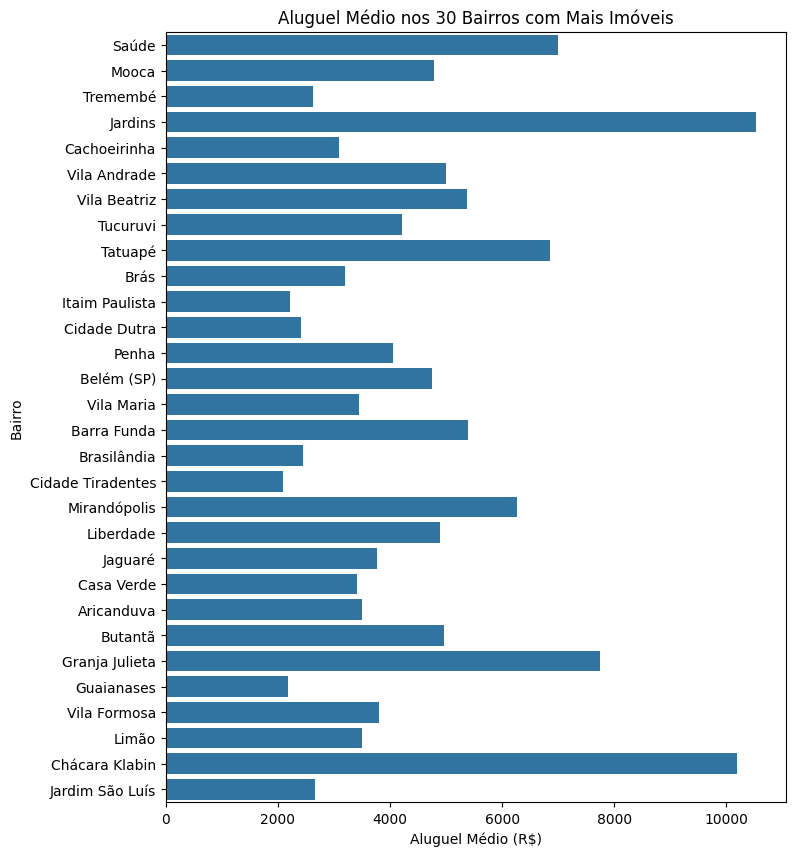

In [62]:

fig, ax = plt.subplots(figsize=(8, 10))

sns.barplot(x=area_top_30.values, y=area_top_30.index, ax=ax, color="C0")

ax.set_title("Aluguel Médio nos 30 Bairros com Mais Imóveis")
ax.set_xlabel("Aluguel Médio (R$)")
ax.set_ylabel("Bairro")
plt.show()

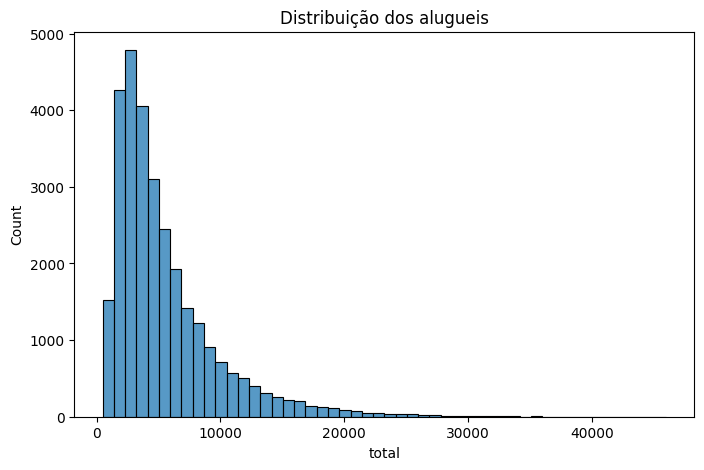

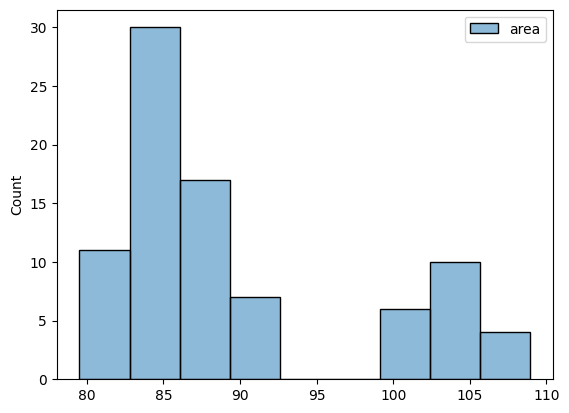

In [89]:

fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(imoveis["total"], bins=50)
ax.set_title("Distribuição dos alugueis")
plt.show()
sns.histplot(imoveis.groupby("bairro")[["area"]].mean())
ax.set_title("Distribuição das áreas")


plt.show()

Aqui percebemos que temos valores de alugueis com presença de outliers.
Já em relação as áreas, temos uma distribuição bimodal



## 3. Como estão distribuídos os valores embutidos no aluguel por bairro?

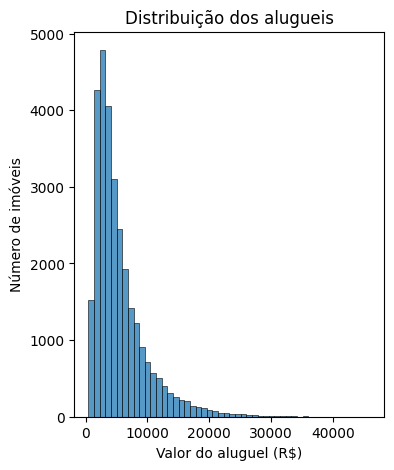

In [56]:
fig, ax = plt.subplots(figsize=(4, 5))

sns.histplot(imoveis["total"], bins=50)
ax.set_title("Distribuição dos alugueis")
ax.set_xlabel("Valor do aluguel (R$)")
ax.set_ylabel("Número de imóveis")
plt.show()




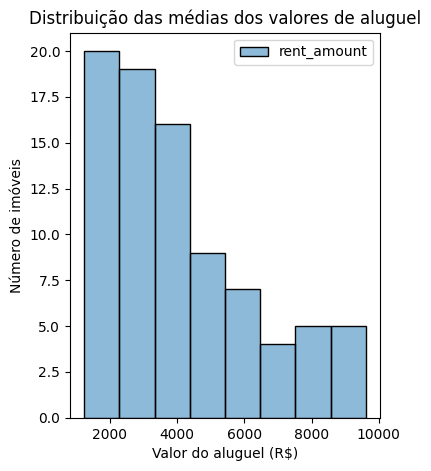

In [59]:
fig, ax = plt.subplots(figsize=(4, 5))

sns.histplot(imoveis.groupby("bairro")[["rent_amount"]].mean())
ax.set_title("Distribuição das médias dos valores de aluguel")
ax.set_xlabel("Valor do aluguel (R$)")
ax.set_ylabel("Número de imóveis")
plt.show()


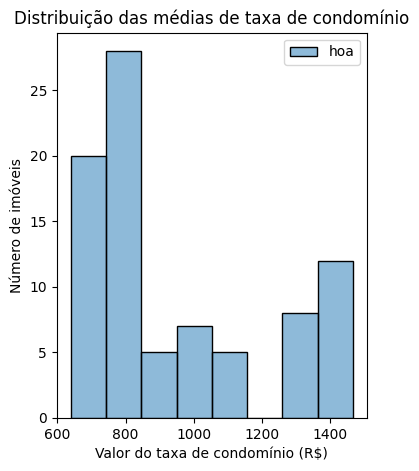

In [60]:
fig, ax = plt.subplots(figsize=(4, 5))

sns.histplot(imoveis.groupby("bairro")[["hoa"]].mean())
ax.set_title("Distribuição das médias de taxa de condomínio")
ax.set_xlabel("Valor do taxa de condomínio (R$)")
ax.set_ylabel("Número de imóveis")
plt.show()

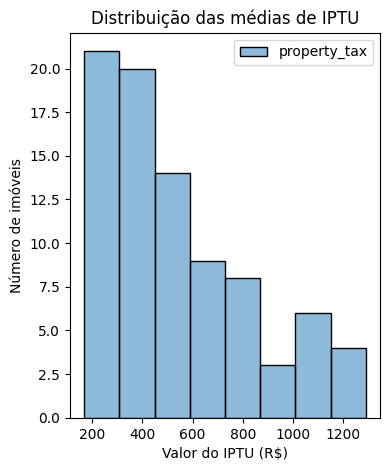

In [61]:

fig, ax = plt.subplots(figsize=(4, 5))

sns.histplot(imoveis.groupby("bairro")[["property_tax"]].mean())
ax.set_title("Distribuição das médias de IPTU")
ax.set_xlabel("Valor do IPTU (R$)")
ax.set_ylabel("Número de imóveis")
plt.show()

*Escreva aqui sua interpretação.*

## 4. Em quais bairros se concentram os imóveis com maior valor de aluguel?

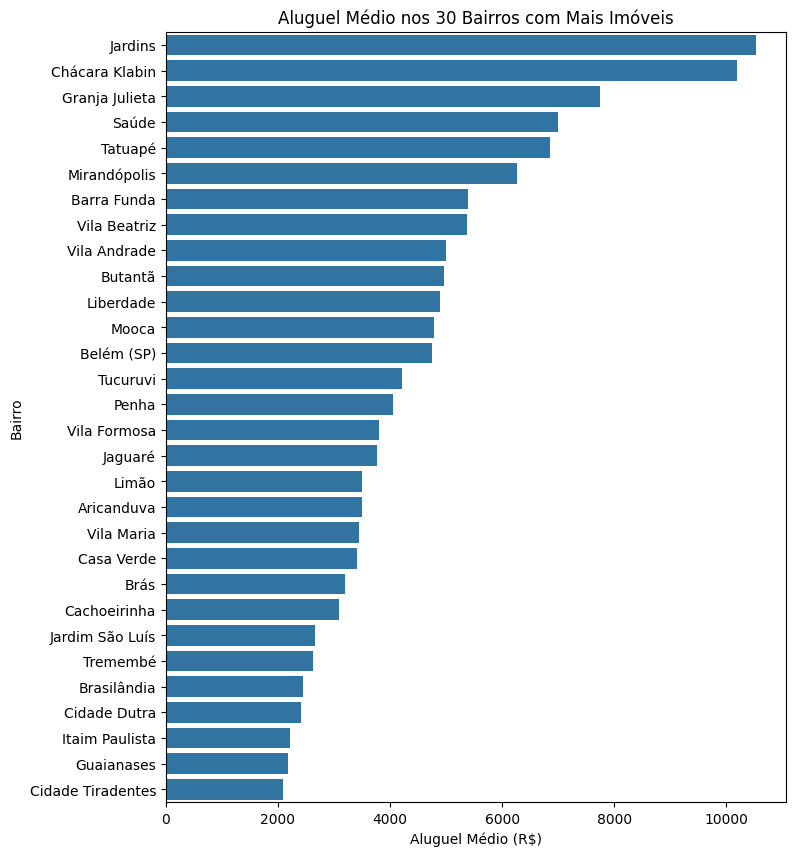

In [65]:
area_top_30 = area_top_30.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 10))
sns.barplot(
    x=area_top_30.values, y=area_top_30.index, ax=ax, color="C0"
)
ax.set_title("Aluguel Médio nos 30 Bairros com Mais Imóveis")
ax.set_xlabel("Aluguel Médio (R$)")
ax.set_ylabel("Bairro")
plt.show()

*Escreva aqui sua interpretação.*

## 5. Como estão distribuídos os valores de aluguel dos imóveis, considerando se são mobiliados ou não?

furniture - é uma variável que não é numérica, antes de avaliar, precisamos criar uma nova coluna com valores numéricos para
"not furnished" - 0
"furnished" - 1

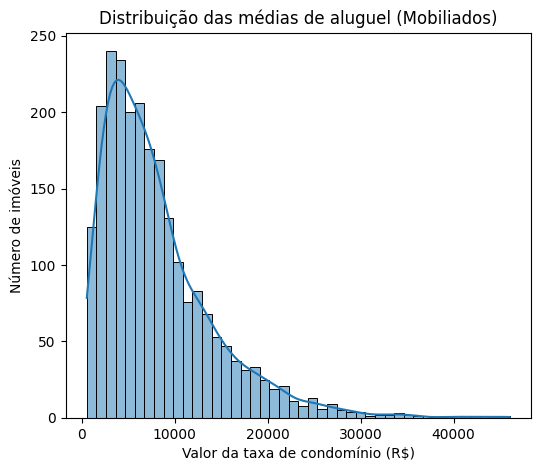

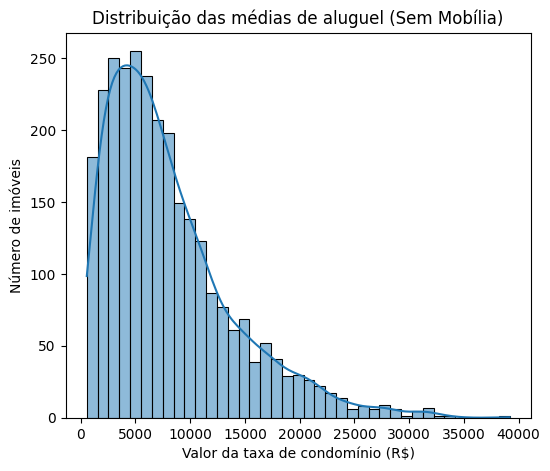

In [90]:

imoveis['furniture_num'] = imoveis['furniture'].map({'not furnished': 0, 'furnished': 1})

mobiliados = imoveis[imoveis['furniture_num'] == 1]
mean_mobiliados = mobiliados.groupby('hoa')['total'].mean()

fig, ax = plt.subplots(figsize=(6, 5))
sns.histplot(mean_mobiliados, ax=ax, kde=True)
ax.set_title("Distribuição das médias de aluguel (Mobiliados)")
ax.set_xlabel("Valor da taxa de condomínio (R$)")
ax.set_ylabel("Número de imóveis")
plt.show()

sem_mobilia = imoveis[imoveis['furniture_num'] == 0]
mean_sem_mobilia = sem_mobilia.groupby('hoa')['total'].mean()

fig, ax = plt.subplots(figsize=(6, 5))
sns.histplot(mean_sem_mobilia, ax=ax, kde=True)
ax.set_title("Distribuição das médias de aluguel (Sem Mobília)")
ax.set_xlabel("Valor da taxa de condomínio (R$)")
ax.set_ylabel("Número de imóveis")
plt.show()


*Escreva aqui sua interpretação.*

## 6. Existe diferença relevante no valor do aluguel entre as zonas da cidade?

In [ ]:


fig, ax = plt.subplots(figsize=(4, 5))
sns.histplot(imoveis.groupby("hoa")[["zona"]])
ax.set_title("Distribuição das médias de aluguel mobiliados")
ax.set_xlabel("Valor do taxa de condomínio (R$)")
ax.set_ylabel("Número de imóveis")
plt.show()

*Escreva aqui sua interpretação.*

## 7. Comparando imóveis no mesmo bairro, casas custam mais ou menos que apartamentos?

In [ ]:
# Escreva aqui o código

*Escreva aqui sua interpretação.*

## 8. Prédios mais altos têm aluguel por m² mais caro que prédios baixos?

In [ ]:
preco_por_andar = imoveis.groupby("total")["total_floors"].mean()

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=preco_por_andar, x="andar", y="aluguel_m2", ax=ax, marker="o")

ax.set_title("Preço Médio do m² por Andar/Altura do Prédio")
ax.set_xlabel("Andar / Altura")
ax.set_ylabel("Aluguel por m² (R$)")
plt.show()


*Escreva aqui sua interpretação.*

## 9. A distância até a estação de metrô/trem mais próxima está associada ao valor do aluguel?

In [ ]:
# Escreva aqui o código

*Escreva aqui sua interpretação.*

# Desafio (opcional)

> **Tip**
>
> Esta seção é bônus: não fazê-la não tira ponto das 9 perguntas
> anteriores. Por outro lado, fazê-la bem soma pontos extras. A correção
> considera relevância/originalidade da pergunta, a justificativa de
> negócio e a qualidade da execução (código + interpretação).

Formule sua própria pergunta de negócio sobre o mercado de aluguel em
São Paulo — diferente das 9 anteriores — que ajude a diretoria a decidir
sobre a expansão. Justifique em 1-2 frases por que essa pergunta importa
antes de respondê-la, com o mesmo padrão das demais seções (código,
resultado e interpretação escrita).

*Escreva aqui sua pergunta e sua justificativa.*

In [ ]:
# Escreva aqui o código

*Escreva aqui sua interpretação.*

> **Antes de entregar**
>
> -   Use Restart Kernel and Run All (ou “Ambiente de execução \>
>     Executar tudo” no Colab) para garantir que todas as células
>     executam em sequência, do início ao fim, sem depender de execuções
>     fora de ordem.
> -   Releia cada interpretação escrita como se um diretor sem formação
>     técnica fosse lê-la: ela responde à pergunta feita, sem jargão
>     estatístico não explicado?